In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sweetviz as sv
from matplotlib.ticker import MaxNLocator
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans

In [2]:
# Load the dataset
df = pd.read_csv('0xc18360217d8f7ab5e7c516566761ea12ce7f9d72.csv')
df.head()

,ts,tsid,from_address,to_address,value,price
0,2024-12-08 16:10:23,0xfdfdd31237021ef336518dd11183ae3d7276ab9ab6ca...,0xc419733Ba8F13d8605141Cac8f681F5A0aBC0122,0xaB782bc7D4a2b306825de5a7730034F8F63ee1bC,2000.00,41.586241
1,2024-12-08 16:09:47,0x4af9dedcbe87099fabe488b8a0c7414bce9a4125fc37...,0x6cC5F688a315f3dC28A7781717a9A798a59fDA7b,0x648e9390D7dBF9eE00E606b0a62e77c58f767A40,460.49,41.586241
2,2024-12-08 16:06:35,0xe6679c8148a14d70b0ba50ac50a0344744bde8469849...,0x6d92FCbDDec7BB03f0B0B4744d2FbA94489Fb4df,0xb3e8c75912438c2282e0aFA51B41Bff8E835Bc88,673.50,41.586241
3,2024-12-08 16:06:23,0xec7c47cab01c36a5d34e96ee43f67dbdd60af794fc9e...,0x10522336d85Cb52628C84e06CB05f79011FEf585,0xb3e8c75912438c2282e0aFA51B41Bff8E835Bc88,904.30,41.586241
4,2024-12-08 16:04:59,0x8ec4646ba436055a842b48406540e33ae4e793f54f87...,0xf5213a6a2f0890321712520b8048D9886c1A9900,0xe71cAB44917bF40B072B47138a76006558Cb29C6,1432.33,41.586241


In [3]:
df.tail()

,ts,tsid,from_address,to_address,value,price
1079824,2021-11-02 00:59:16,0x1938a3b85d114cb0113fb9c450e7b46080db449a9761...,0x0904Dac3347eA47d208F3Fd67402D039a3b99859,0x40790dB8c3e62f99E24E3Fe9C5e9af297Ed57780,128730.01,NaN
1079825,2021-11-01 21:20:18,0x06bb6d2a3353120b054020539504049ad735963561cf...,0x0904Dac3347eA47d208F3Fd67402D039a3b99859,0xFe89cc7aBB2C4183683ab71653C4cdc9B02D44b7,5000000.00,NaN
1079826,2021-11-01 21:19:47,0x9492a233a0ec33a5fddb0b63adea2b25af49aba3e12d...,0x0904Dac3347eA47d208F3Fd67402D039a3b99859,0xd7A029Db2585553978190dB5E85eC724Aa4dF23f,45000000.00,NaN
1079827,2021-11-01 20:55:17,0xdfc76788b13ab1c033c7cd55fdb7a431b2bc8abe6b19...,0x0000000000000000000000000000000000000000,0xC18360217D8F7Ab5e7c516566761Ea12Ce7F9D72,25000000.00,NaN
1079828,2021-11-01 20:55:17,0xdfc76788b13ab1c033c7cd55fdb7a431b2bc8abe6b19...,0x0000000000000000000000000000000000000000,0x0904Dac3347eA47d208F3Fd67402D039a3b99859,75000000.00,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1079829 entries, 0 to 1079828
Data columns (total 6 columns):
 #   Column        Non-Null Count    Dtype  
---  ------        --------------    -----  
 0   ts            1079829 non-null  object 
 1   tsid          1079829 non-null  object 
 2   from_address  1079829 non-null  object 
 3   to_address    1079829 non-null  object 
 4   value         1079829 non-null  float64
 5   price         1079753 non-null  float64
dtypes: float64(2), object(4)
memory usage: 49.4+ MB


In [5]:
# Remove rows with missing values
df = df.dropna()
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1079753 entries, 0 to 1079752
Data columns (total 6 columns):
 #   Column        Non-Null Count    Dtype  
---  ------        --------------    -----  
 0   ts            1079753 non-null  object 
 1   tsid          1079753 non-null  object 
 2   from_address  1079753 non-null  object 
 3   to_address    1079753 non-null  object 
 4   value         1079753 non-null  float64
 5   price         1079753 non-null  float64
dtypes: float64(2), object(4)
memory usage: 57.7+ MB


In [6]:
# Convert the ts column to datetime
df['ts'] = pd.to_datetime(df['ts'])

In [7]:
# Calculate the balance change for each transaction: Balance = Value * Price
df['balance_change'] = df['value'] * df['price']
df

,ts,tsid,from_address,to_address,value,price,balance_change
0,2024-12-08 16:10:23,0xfdfdd31237021ef336518dd11183ae3d7276ab9ab6ca...,0xc419733Ba8F13d8605141Cac8f681F5A0aBC0122,0xaB782bc7D4a2b306825de5a7730034F8F63ee1bC,2000.000000,41.586241,83172.481890
1,2024-12-08 16:09:47,0x4af9dedcbe87099fabe488b8a0c7414bce9a4125fc37...,0x6cC5F688a315f3dC28A7781717a9A798a59fDA7b,0x648e9390D7dBF9eE00E606b0a62e77c58f767A40,460.490000,41.586241,19150.048093
2,2024-12-08 16:06:35,0xe6679c8148a14d70b0ba50ac50a0344744bde8469849...,0x6d92FCbDDec7BB03f0B0B4744d2FbA94489Fb4df,0xb3e8c75912438c2282e0aFA51B41Bff8E835Bc88,673.500000,41.586241,28008.333276
3,2024-12-08 16:06:23,0xec7c47cab01c36a5d34e96ee43f67dbdd60af794fc9e...,0x10522336d85Cb52628C84e06CB05f79011FEf585,0xb3e8c75912438c2282e0aFA51B41Bff8E835Bc88,904.300000,41.586241,37606.437686
4,2024-12-08 16:04:59,0x8ec4646ba436055a842b48406540e33ae4e793f54f87...,0xf5213a6a2f0890321712520b8048D9886c1A9900,0xe71cAB44917bF40B072B47138a76006558Cb29C6,1432.330000,41.586241,59565.220493
...,...,...,...,...,...,...,...
1079748,2021-11-09 00:01:56,0xa8a0b3030860f4970c6ac4b0e5e3dbad877fef2b41ca...,0xC18360217D8F7Ab5e7c516566761Ea12Ce7F9D72,0x3839AcF1ee7699D1F46b1BE840D8aD8317FDf757,735.490276,43.436425,31947.068536
1079749,2021-11-09 00:01:56,0x5a067ac5c5d6aeb5acae38ff66d99901826db1e4bef9...,0xC18360217D8F7Ab5e7c516566761Ea12Ce7F9D72,0x12e245BF546D91Bc25Fc18c9252cD0dE8b44dC9B,130.128002,43.436425,5652.295247
1079750,2021-11-09 00:01:43,0x57458e828809dc0efa892a507310cc1817151c2f6594...,0xC18360217D8F7Ab5e7c516566761Ea12Ce7F9D72,0x0904Dac3347eA47d208F3Fd67402D039a3b99859,1143.544204,43.436425,49671.472593
1079751,2021-11-09 00:01:26,0x9169befc5bb7af4437bcd31569ffcc33c38609b44554...,0xC18360217D8F7Ab5e7c516566761Ea12Ce7F9D72,0xA753e050948Ff5BfB4b695f870B3407f85F6DEF1,430.605923,43.436425,18703.982076


In [8]:
# Combine from_address and to_address for further analysis
# and to inspect the balance of each individual wallet
combined = [val for pair in zip(df['from_address'], df['to_address']) for val in pair]
df_combined = pd.DataFrame(combined, columns=['address'])
df_combined['ts'] = df['ts'].repeat(2).reset_index(drop=True)
df_combined

,address,ts
0,0xc419733Ba8F13d8605141Cac8f681F5A0aBC0122,2024-12-08 16:10:23
1,0xaB782bc7D4a2b306825de5a7730034F8F63ee1bC,2024-12-08 16:10:23
2,0x6cC5F688a315f3dC28A7781717a9A798a59fDA7b,2024-12-08 16:09:47
3,0x648e9390D7dBF9eE00E606b0a62e77c58f767A40,2024-12-08 16:09:47
4,0x6d92FCbDDec7BB03f0B0B4744d2FbA94489Fb4df,2024-12-08 16:06:35
...,...,...
2159501,0x0904Dac3347eA47d208F3Fd67402D039a3b99859,2021-11-09 00:01:43
2159502,0xC18360217D8F7Ab5e7c516566761Ea12Ce7F9D72,2021-11-09 00:01:26
2159503,0xA753e050948Ff5BfB4b695f870B3407f85F6DEF1,2021-11-09 00:01:26
2159504,0x39Ff98b5e9DA4f59eb056E23aAd0Fe5E9165a357,2021-11-09 00:00:16


In [9]:
# Assign the balance change: negative for the sender address,
# positive for the recipient address
df_c = []
for c in df['balance_change']:
    df_c.append(-c)  # Add the negative value
    df_c.append(c)   # Add the original value

In [10]:
# Create a new dataset containing wallet addresses
df_new = pd.DataFrame(df_c, columns=['balance_change'])
df_result = pd.concat([df_combined, df_new], axis=1)
df_result.head()

,address,ts,balance_change
0,0xc419733Ba8F13d8605141Cac8f681F5A0aBC0122,2024-12-08 16:10:23,-83172.481890
1,0xaB782bc7D4a2b306825de5a7730034F8F63ee1bC,2024-12-08 16:10:23,83172.481890
2,0x6cC5F688a315f3dC28A7781717a9A798a59fDA7b,2024-12-08 16:09:47,-19150.048093
3,0x648e9390D7dBF9eE00E606b0a62e77c58f767A40,2024-12-08 16:09:47,19150.048093
4,0x6d92FCbDDec7BB03f0B0B4744d2FbA94489Fb4df,2024-12-08 16:06:35,-28008.333276


In [11]:
df_result.info

<bound method DataFrame.info of                                             address                  ts   
0        0xc419733Ba8F13d8605141Cac8f681F5A0aBC0122 2024-12-08 16:10:23  \
1        0xaB782bc7D4a2b306825de5a7730034F8F63ee1bC 2024-12-08 16:10:23   
2        0x6cC5F688a315f3dC28A7781717a9A798a59fDA7b 2024-12-08 16:09:47   
3        0x648e9390D7dBF9eE00E606b0a62e77c58f767A40 2024-12-08 16:09:47   
4        0x6d92FCbDDec7BB03f0B0B4744d2FbA94489Fb4df 2024-12-08 16:06:35   
...                                             ...                 ...   
2159501  0x0904Dac3347eA47d208F3Fd67402D039a3b99859 2021-11-09 00:01:43   
2159502  0xC18360217D8F7Ab5e7c516566761Ea12Ce7F9D72 2021-11-09 00:01:26   
2159503  0xA753e050948Ff5BfB4b695f870B3407f85F6DEF1 2021-11-09 00:01:26   
2159504  0x39Ff98b5e9DA4f59eb056E23aAd0Fe5E9165a357 2021-11-09 00:00:16   
2159505  0xdE8DcD65042db880006421dD3ECA5D94117642d1 2021-11-09 00:00:16   

         balance_change  
0         -83172.481890  
1          8317

In [12]:
# Find the most active wallet addresses, i.e. those with the highest transaction counts
popular_values = df_result['address'].value_counts()
popular_values

address
0x92560C178cE069CC014138eD3C2F5221Ba71f58a    212951
0xC18360217D8F7Ab5e7c516566761Ea12Ce7F9D72    102915
0x74de5d4FCbf63E00296fd95d33236B9794016631     76332
0xa1181481bEb2dc5De0DaF2c85392d81C704BF75D     74642
0x28C6c06298d514Db089934071355E5743bf21d60     73772
                                               ...  
0x1D13177E4EA3ced21d93CE90e73dFccda7b2142C         1
0x56792A113535c3ce06EBd9777A4c8613a4552e18         1
0x5c531eBAB2402D8f891C8727276E8cd871e80134         1
0xbe12Fb92d5d68e4b1A60Fc15b827Cb8868257E47         1
0x39Ff98b5e9DA4f59eb056E23aAd0Fe5E9165a357         1
Name: count, Length: 245532, dtype: int64

In [13]:
# Keep records for the wallet address 0x28C6c06298d514Db089934071355E5743bf21d60
filtered_df = df_result[df_result['address'] == '0x28C6c06298d514Db089934071355E5743bf21d60']
filtered_df

,address,ts,balance_change
25,0x28C6c06298d514Db089934071355E5743bf21d60,2024-12-08 16:00:11,38575.397100
31,0x28C6c06298d514Db089934071355E5743bf21d60,2024-12-08 15:55:59,38221.914052
33,0x28C6c06298d514Db089934071355E5743bf21d60,2024-12-08 15:55:59,83172.481890
45,0x28C6c06298d514Db089934071355E5743bf21d60,2024-12-08 15:50:59,100525.423652
47,0x28C6c06298d514Db089934071355E5743bf21d60,2024-12-08 15:50:59,13536.321428
...,...,...,...
1833361,0x28C6c06298d514Db089934071355E5743bf21d60,2021-11-11 08:32:16,70672.628790
1833363,0x28C6c06298d514Db089934071355E5743bf21d60,2021-11-11 08:32:16,3757.211625
1833365,0x28C6c06298d514Db089934071355E5743bf21d60,2021-11-11 08:32:16,33623.632499
1833367,0x28C6c06298d514Db089934071355E5743bf21d60,2021-11-11 08:32:16,17585.645276


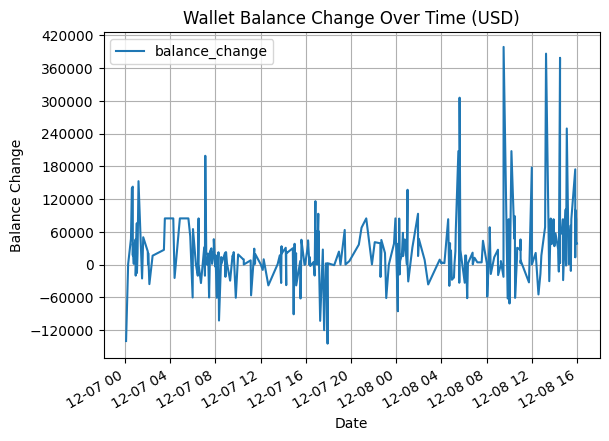

In [14]:
# Select the time range starting from December 7, 2024
df_time = filtered_df[filtered_df['ts'] > '2024-12-07 00:00']

# Plot the selected wallet's balance changes over time
df_time.plot(x='ts', y='balance_change', kind='line')

# Configure the plot
plt.title('Wallet Balance Change Over Time (USD)')
plt.xlabel('Date')
plt.ylabel('Balance Change')
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))  # Use integer tick values
plt.ticklabel_format(style='plain', axis='y')  # Disable scientific notation
plt.grid(True)

# Display the plot
plt.show()

In [15]:
# Save the transaction history for wallet 0x28C6c06298d514Db089934071355E5743bf21d60 to Excel
filtered_df.to_excel('0x28C6c06298d514Db089934071355E5743bf21d60.xlsx', index=False)

In [16]:
# Calculate the count, minimum, maximum, mean, median, and standard deviation
# for each unique record

# Group by address and aggregate the balance_change column
summary = df_result.groupby('address').agg(
    count_balance_change=('balance_change', 'count'),
    min_balance_change=('balance_change', 'min'),
    max_balance_change=('balance_change', 'max'),
    mean_balance_change=('balance_change', 'mean'),
    median_balance_change=('balance_change', 'median'),
    std_balance_change=('balance_change', 'std'),
    last_ts=('ts', 'max')
)

summary['std_balance_change'] = summary['std_balance_change'].fillna(0)
summary = summary.reset_index()
summary

,address,count_balance_change,min_balance_change,max_balance_change,mean_balance_change,median_balance_change,std_balance_change,last_ts
0,0x000000000000000000000000000000000000dEaD,3,0.469551,22.066719,8.185481e+00,2.020172,12.046480,2023-08-08 14:52:23
1,0x000000000000000000000000003affE2c2a31dBb,1,242.413707,242.413707,2.424137e+02,242.413707,0.000000,2022-10-11 16:13:11
2,0x00000000000006b2AB6deCBC6FC7Ec6bD2Fbc720,4,-2745.965932,2745.965932,0.000000e+00,0.000000,2461.818647,2024-01-10 16:37:35
3,0x0000000000000Eb4ec62758aaE93400B3E5f7f18,8,-10869.815262,10869.815262,0.000000e+00,0.000000,9137.842870,2021-11-10 16:51:06
4,0x00000000000030e5959659622Cb7eb50AA20Ee52,2,-1008.284260,1008.284260,0.000000e+00,0.000000,1425.929276,2023-03-05 08:46:59
...,...,...,...,...,...,...,...,...
245527,0xfffFFc03E9D2c7F163135D2b0F18FC7F27c43cCE,3,-929.406343,4456.934800,1.169684e+03,-18.475752,2883.047145,2022-06-24 07:38:03
245528,0xfffaA912b2740381eB753A03E9c13c661CeFC0ed,3,-35395.615235,23235.504434,3.555529e+03,22826.698609,33733.299930,2021-11-22 14:55:32
245529,0xfffcfF9cFc240ff3E6657f4F2e0902E12ae666e8,2,-431.857851,431.857851,0.000000e+00,0.000000,610.739230,2024-05-03 10:55:11
245530,0xffff0c6FEBddBAb590Ad077096d87cE806aaCe47,2,-4247.965462,4247.965462,0.000000e+00,0.000000,6007.530368,2021-11-10 15:56:27


In [17]:
# Normalize the transaction count and mean balance change
normalized_data = normalize(summary[['count_balance_change', 'mean_balance_change']], axis=0)

# Create a new DataFrame with the normalized data
norm_df = pd.DataFrame(normalized_data, columns=['count_balance_change', 'mean_balance_change'])
norm_df.head()

,count_balance_change,mean_balance_change
0,0.000010,6.623710e-07
1,0.000003,1.961617e-05
2,0.000014,0.000000e+00
3,0.000027,0.000000e+00
4,0.000007,0.000000e+00


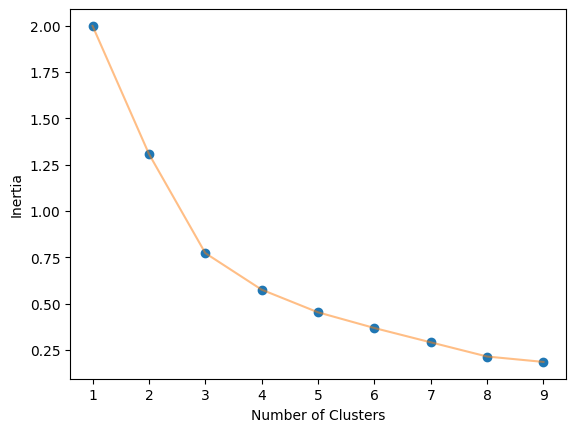

In [18]:
# Use the elbow method to find the optimal number of clusters
def elbow_plot(data, clusters):
    inertia = []
    for n in range(1, clusters):
        algorithm = KMeans(
            n_clusters=n,
            init="k-means++",
            random_state=125,
        )
        algorithm.fit(data)
        inertia.append(algorithm.inertia_)

    plt.plot(np.arange(1, clusters), inertia, 'o')
    plt.plot(np.arange(1, clusters), inertia, '-', alpha=0.5)
    plt.xlabel('Number of Clusters')
    plt.ylabel('Inertia')
    plt.show()

elbow_plot(norm_df, 10)

In [19]:
# Cluster the data into three groups
kmeans = KMeans(3, random_state=125)
clusters = kmeans.fit_predict(norm_df)

In [20]:
# Add cluster labels to the DataFrame
labels = pd.DataFrame({'Cluster': clusters})
labeled_summary = pd.concat((summary, labels), axis=1)
labeled_summary['Cluster'] = labeled_summary['Cluster'].astype(str)
labeled_summary.head()

,address,count_balance_change,min_balance_change,max_balance_change,mean_balance_change,median_balance_change,std_balance_change,last_ts,Cluster
0,0x000000000000000000000000000000000000dEaD,3,0.469551,22.066719,8.185481,2.020172,12.046480,2023-08-08 14:52:23,0
1,0x000000000000000000000000003affE2c2a31dBb,1,242.413707,242.413707,242.413707,242.413707,0.000000,2022-10-11 16:13:11,0
2,0x00000000000006b2AB6deCBC6FC7Ec6bD2Fbc720,4,-2745.965932,2745.965932,0.000000,0.000000,2461.818647,2024-01-10 16:37:35,0
3,0x0000000000000Eb4ec62758aaE93400B3E5f7f18,8,-10869.815262,10869.815262,0.000000,0.000000,9137.842870,2021-11-10 16:51:06,0
4,0x00000000000030e5959659622Cb7eb50AA20Ee52,2,-1008.284260,1008.284260,0.000000,0.000000,1425.929276,2023-03-05 08:46:59,0


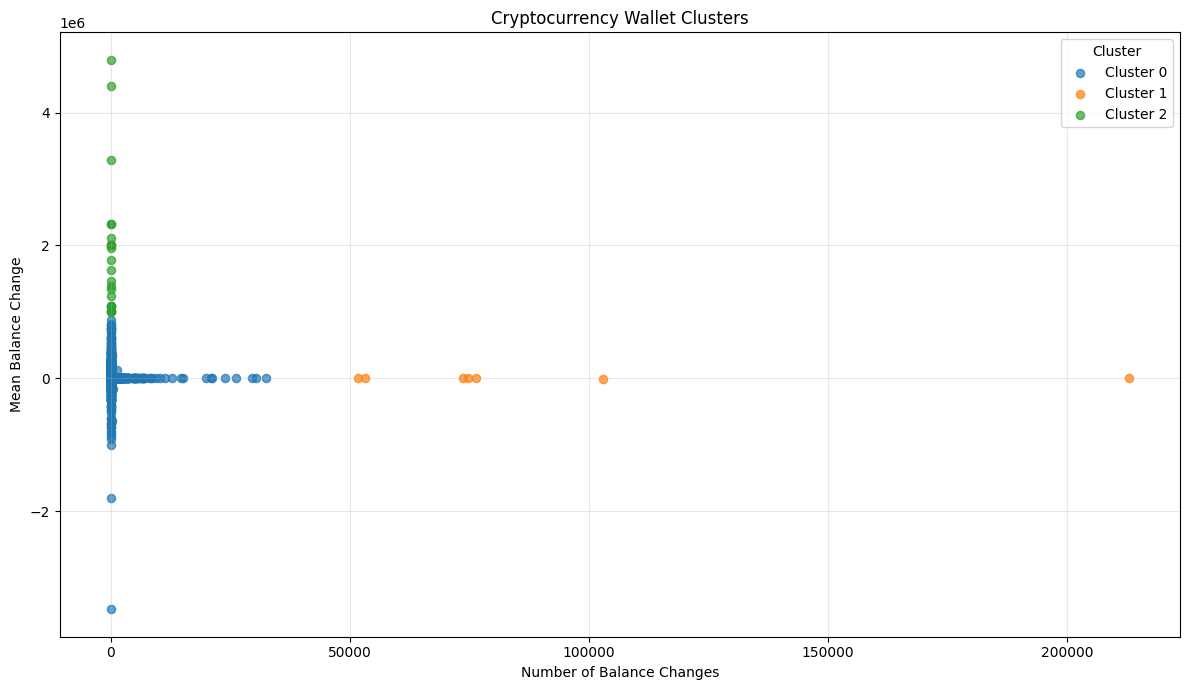

In [21]:
# Plot the clustering results using Matplotlib
fig, ax = plt.subplots(figsize=(12, 7))

for cluster in sorted(labeled_summary['Cluster'].unique()):
    cluster_data = labeled_summary[labeled_summary['Cluster'] == cluster]
    ax.scatter(
        cluster_data['count_balance_change'],
        cluster_data['mean_balance_change'],
        label=f'Cluster {cluster}',
        alpha=0.7,
        s=35
    )

ax.set_title('Cryptocurrency Wallet Clusters')
ax.set_xlabel('Number of Balance Changes')
ax.set_ylabel('Mean Balance Change')
ax.legend(title='Cluster')
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

In [22]:
# Save the clustering results to Excel
labeled_summary.to_excel('labeled_summary.xlsx', index=False)

In [23]:
# Generate a report of the results
report = sv.analyze(labeled_summary)
report.show_html('report.html', open_browser=True)

                                             |                                             | [  0%]   00:00 ->…

Report report.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.
